In [1]:
import os
from dotenv import load_dotenv
load_dotenv()
from langchain_openai import ChatOpenAI

from dotenv import load_dotenv

if os.environ['AICREDITS_API_KEY']:
    print("AICredits API Key is set.")
else:
    raise ValueError("AICredits API Key is not set.")

AICredits API Key is set.


In [2]:
from langchain.messages import HumanMessage


llm = ChatOpenAI(
    model="openai/gpt-5-nano",
    base_url="https://api.aicredits.in/v1",
    api_key=os.environ["AICREDITS_API_KEY"],
)

llm.invoke([HumanMessage(content="I want to know the meaning of water")]).content

'Here are a few ways to understand “water”:\n\n- Scientific meaning\n  - Water is a chemical substance with the formula H2O: two hydrogen atoms bonded to one oxygen.\n  - It’s a liquid at standard room temperature and pressure, essential for all known life.\n  - Important properties: high surface tension, strong hydrogen bonding, a high heat capacity, and the density anomaly (ice is less dense than liquid water, so ice floats).\n  - It’s often called the “universal solvent” because many substances dissolve in it.\n\n- Natural occurrence\n  - Water covers about 71% of Earth’s surface (oceans, rivers, lakes, groundwater, humidity in the air).\n  - It cycles through evaporation, condensation, precipitation, and collection (the water cycle).\n\n- Etymology\n  - The word comes from Old English “wæter,” related to many Germanic languages (German Wasser, Dutch water). The roots go back to Proto-Indo-European.\n\n- Cultural and symbolic meanings\n  - Water often symbolizes life, cleansing, ren

In [3]:
from typing import Annotated, List, TypedDict
from operator import add

class graph_schema(TypedDict):
    messages_manual: List
    messages_auto: Annotated[List, add]


In [ ]:
from langchain_core.messages import AIMessage

def create_post(state: graph_schema) -> graph_schema:
    messages_manual = state['messages_manual']
    response_manual = llm.invoke(messages_manual).content
    response__manual_ai = AIMessage(content=response_manual)
    state['messages_manual'] = messages_manual + [response__manual_ai]

    messages_auto = state['messages_auto']
    response_auto = llm.invoke(messages_auto).content
    response_auto_ai = AIMessage(content=response_auto) 
    state['messages_auto'] = [response_auto_ai]

    return state

def curate_post(state: graph_schema) -> graph_schema:
    messages_manual = state['messages_manual']
    response_manual = llm.invoke(messages_manual).content
    response__manual_ai = AIMessage(content=response_manual)
    state['messages_manual'] = messages_manual + [response__manual_ai]

    messages_auto = state['messages_auto']
    response_auto = llm.invoke(messages_auto).content
    response_auto_ai = AIMessage(content=response_auto)
    state['messages_auto'] = [response_auto_ai]

    return state


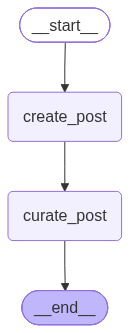

In [ ]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_schema)

graph.add_node("create_post", create_post)
graph.add_node("curate_post", curate_post)####fsdafdsfsdfsddsfds

graph.add_edge(START, "create_post")
graph.add_edge("create_post", "curate_post")
graph.add_edge("curate_post", END)

messages_graph = graph.compile()



from IPython.display import Image, display

# You could see the errors with the below command
Image(messages_graph.get_graph().draw_mermaid_png())

In [6]:
messages_graph.invoke(
    {"messages_manual": [HumanMessage(content="The importance of data privacy in the digital age")],
     "messages_auto": [HumanMessage(content="The importance of data privacy in the digital age")]}
)

{'messages_manual': [HumanMessage(content='The importance of data privacy in the digital age', additional_kwargs={}, response_metadata={}),
  AIMessage(content="Data privacy in the digital age refers to your control over personal information—what is collected, how it’s used, who sees it, and how long it’s kept. Because so much of daily life now happens online, protecting privacy isn't just about keeping secrets; it's about safety, autonomy, and trust.\n\nWhy data privacy matters\n- Personal autonomy and dignity: Your data can reveal sensitive details about health, finances, beliefs, relationships, and routines. When that information is exposed or misused, it can limit choices and threaten dignity.\n- Security and safety: Data breaches, identity theft, and fraudulent activity often hinge on exposed personal data such as passwords, financial info, or security questions.\n- Fairness and non-discrimination: Data can be used to profile or discriminate (e.g., biased hiring, credit, or insura